# AI Layoffs vs. Hiring (2026) — Analysis Notebook

**Question:** How often did companies cite AI when announcing job cuts in 2026, how did that change over time, and how did the share of job postings mentioning AI move in the same period?

This notebook answers the five research questions with charts. It reads only the **clean** files produced by the scripts in `python/` (see `docs/PROCESS.md`), so every number here matches the SQL layer (`sql/04_checks.sql`, 41/41 checks).

**Rules used throughout**
- Main analysis = `in_main_analysis == True` → 643 announcements, 653,456 people.
- AI share is reported with the **strict** definition (`is_ai_strict`: AI-labelled, label not questionable, number not "up to …"). The **broad** definition (all AI labels) is only an upper bound.
- Wording: *announced job cuts*, not "jobs lost". Trends are shown side by side; **no causal claims**.

| Section | Question |
|---|---|
| 1 | Data and validation at a glance |
| 2 | Q1 — Which industries announced the most job cuts? |
| 3 | Why a strict AI definition? |
| 4 | Q2 — In which industries was AI cited more often? |
| 5 | Q3 — How did the AI share change month by month? (+ Challenger cross-check) |
| 6 | Q4 — Do AI-attributed announcements cover more people? |
| 7 | Q5 — How did the share of job postings mentioning AI change? |
| 8 | Both sides together |
| 9 | How robust are the findings? |
| 10 | Summary and limitations |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, PercentFormatter

DATA = Path("..") / "data" / "clean"
FIG = Path("figures")
FIG.mkdir(exist_ok=True)

# --- Chart style -----------------------------------------------------------------
# Validated categorical palette, used in fixed order (blue, orange, aqua) + neutral greys.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
GREY_SERIES = "#c3c2b7"                      # de-emphasised series
TIER_RAMP = ["#184f95", "#256abf", "#3987e5", "#6da7ec", "#9ec5f4"]  # ordinal blue ramp, T1 -> T5

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "axes.axisbelow": True, "legend.frameon": False, "lines.linewidth": 2,
})
thousands = FuncFormatter(lambda x, _: f"{x:,.0f}")


def source_note(fig, text):
    fig.text(0.0, -0.06, text, ha="left", va="top", fontsize=8, color=MUTED)


def save(fig, name):
    fig.savefig(FIG / f"{name}.png")


layoffs = pd.read_csv(DATA / "layoffs_clean.csv", parse_dates=["announce_date"])
main = layoffs[layoffs["in_main_analysis"]].copy()
monthly = pd.read_csv(DATA / "layoffs_clean_monthly.csv")
industries = pd.read_csv(DATA / "layoffs_clean_industries.csv")
indeed = pd.read_csv(DATA / "ai_posting_monthly.csv")
challenger = pd.read_csv(DATA / "challenger_ai_monthly.csv")
tests = pd.read_csv(DATA / "statistical_tests.csv").set_index("test")

print(f"All rows: {len(layoffs)} | main analysis: {len(main)} rows, {main['people_cut'].sum():,} people, "
      f"{main['company'].nunique()} companies")

All rows: 653 | main analysis: 643 rows, 653,456 people, 561 companies


## 1. Data and validation at a glance

The main source (layoffhedge.com) is little known, so before any analysis the data was **validated by materiality**: every large row (3,000+ people) and every AI-labelled row was compared with news sources, plus a random sample of small rows — 146 rows in total. Nothing was deleted; problems are flagged in columns.

Each row carries one **reliability tier**. The chart shows how much of the analysed volume sits in each tier.

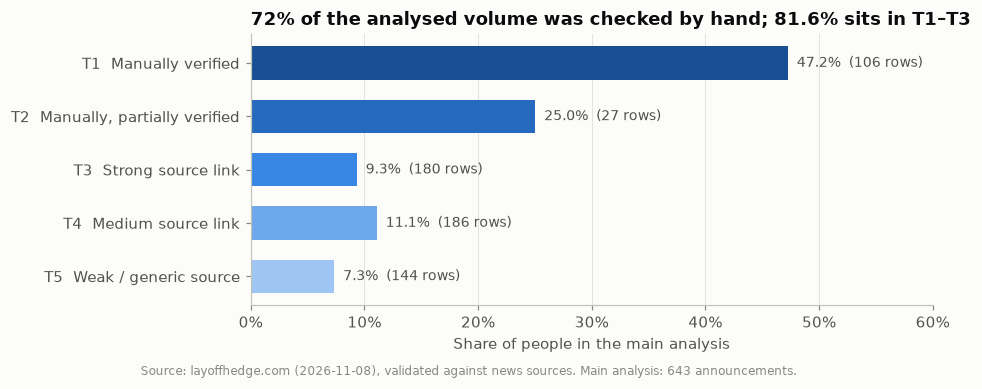

,rows,people,share_pct
reliability_tier,,,
T1_manual_verified,106,308736,47.2
T2_manual_partial,27,163500,25.0
T3_strong_source,180,60883,9.3
T4_medium_source,186,72383,11.1
T5_weak_source,144,47954,7.3


,rows
verification,
verified,104
partial,27
not_found,8
invalid,4
corrected,2
mismatch,1


In [2]:
tier_labels = {
    "T1_manual_verified": "T1  Manually verified",
    "T2_manual_partial": "T2  Manually, partially verified",
    "T3_strong_source": "T3  Strong source link",
    "T4_medium_source": "T4  Medium source link",
    "T5_weak_source": "T5  Weak / generic source",
}
tiers = (main.groupby("reliability_tier")["people_cut"].agg(["size", "sum"])
         .reindex(tier_labels).rename(columns={"size": "rows", "sum": "people"}))
tiers["share_pct"] = tiers["people"] / tiers["people"].sum() * 100

fig, ax = plt.subplots(figsize=(8, 3.2))
y = np.arange(len(tiers))[::-1]
ax.barh(y, tiers["share_pct"], color=TIER_RAMP, height=0.62)
ax.set_yticks(y, [tier_labels[t] for t in tiers.index])
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
for yi, (share, rows) in zip(y, tiers[["share_pct", "rows"]].to_numpy()):
    ax.text(share + 0.8, yi, f"{share:.1f}%  ({rows:.0f} rows)", va="center", fontsize=9, color=INK_2)
ax.set_xlim(0, 60)
ax.set_xlabel("Share of people in the main analysis")
ax.set_title("72% of the analysed volume was checked by hand; 81.6% sits in T1–T3")
source_note(fig, "Source: layoffhedge.com (2026-11-08), validated against news sources. Main analysis: 643 announcements.")
save(fig, "01_reliability_tiers")
plt.show()

verification = layoffs.loc[layoffs["verification"] != "not_checked", "verification"].value_counts()
display(tiers.round(1))
display(verification.rename("rows").to_frame())

**Reading it:** almost half of all announced job cuts (47%) were verified one by one, and another 25% partially (the event is real but the number is a plan or an "up to …" figure). Validation found **4 wrong-year rows** (Intel 2024, Nestlé 2025, Nokia 2023, CrowdStrike 2025 — excluded) and **2 wrong numbers** (Verizon 3,000 → 500, Commerzbank 6,900 → 3,000 — corrected).

## 2. Q1 — Which industries announced the most job cuts in 2026?

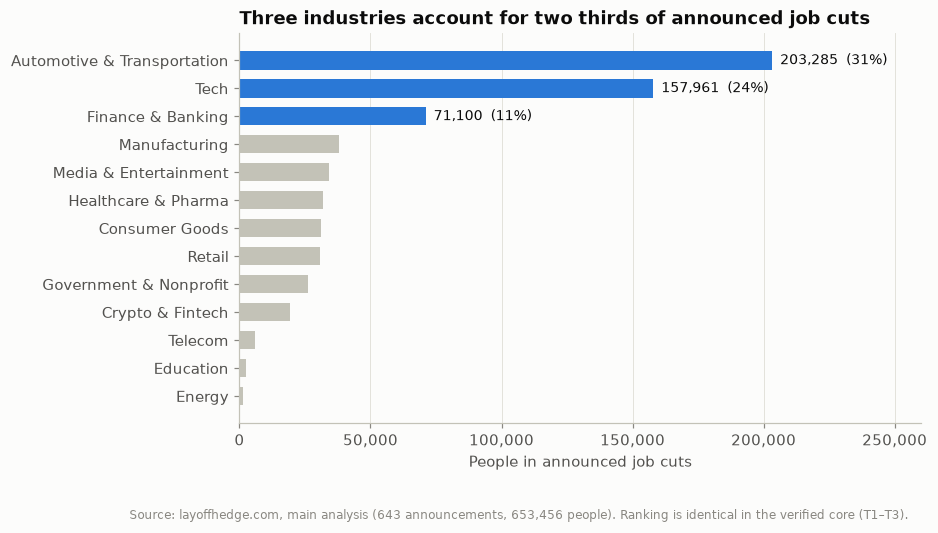

,announcements,companies,people_cut,median_cut
industry,,,,
Automotive & Transportation,65,56,203285,340.0
Tech,139,119,157961,240.0
Finance & Banking,59,51,71100,387.0
Manufacturing,86,80,37868,148.0
Media & Entertainment,62,50,34214,146.5
Healthcare & Pharma,86,75,31750,134.0
Consumer Goods,49,45,31118,170.0
Retail,46,40,30910,273.0
Government & Nonprofit,7,7,26013,200.0


In [3]:
ind = industries.sort_values("people_cut")
top3 = set(ind.nlargest(3, "people_cut")["industry"])
fig, ax = plt.subplots(figsize=(8, 4.6))
colors = [BLUE if i in top3 else GREY_SERIES for i in ind["industry"]]
ax.barh(ind["industry"], ind["people_cut"], color=colors, height=0.66)
ax.xaxis.set_major_formatter(thousands)
ax.grid(axis="y", visible=False)
total = ind["people_cut"].sum()
for i, row in ind.iterrows():
    if row["industry"] in top3:
        ax.text(row["people_cut"] + 3000, row["industry"],
                f"{row['people_cut']:,.0f}  ({row['people_cut'] / total:.0%})", va="center", fontsize=9, color=INK)
ax.set_xlim(0, ind["people_cut"].max() * 1.28)
ax.set_xlabel("People in announced job cuts")
ax.set_title("Three industries account for two thirds of announced job cuts")
source_note(fig, "Source: layoffhedge.com, main analysis (643 announcements, 653,456 people). Ranking is identical in the verified core (T1–T3).")
save(fig, "02_q1_industries")
plt.show()

display(industries[["industry", "announcements", "companies", "people_cut", "median_cut"]].set_index("industry"))

**Answer:** **Automotive & Transportation** (203,285 people, 31%), **Tech** (157,961, 24%) and **Finance & Banking** (71,100, 11%). Automotive is driven by a few giant plans — Volkswagen alone accounts for 100,000. By *number* of announcements Tech leads clearly (139). The ranking is the same at every reliability level (section 9).

## 3. Why a strict AI definition?

The site's own "AI-DRIVEN" label is not always right. Verification showed that some of the largest AI rows either give a **different main reason** (e.g. UPS: reduced Amazon volume; HubSpot: the CEO denies AI) or state an **upper bound** ("up to 30,000"). The chart shows the 15 largest AI-labelled announcements and how each is classified.

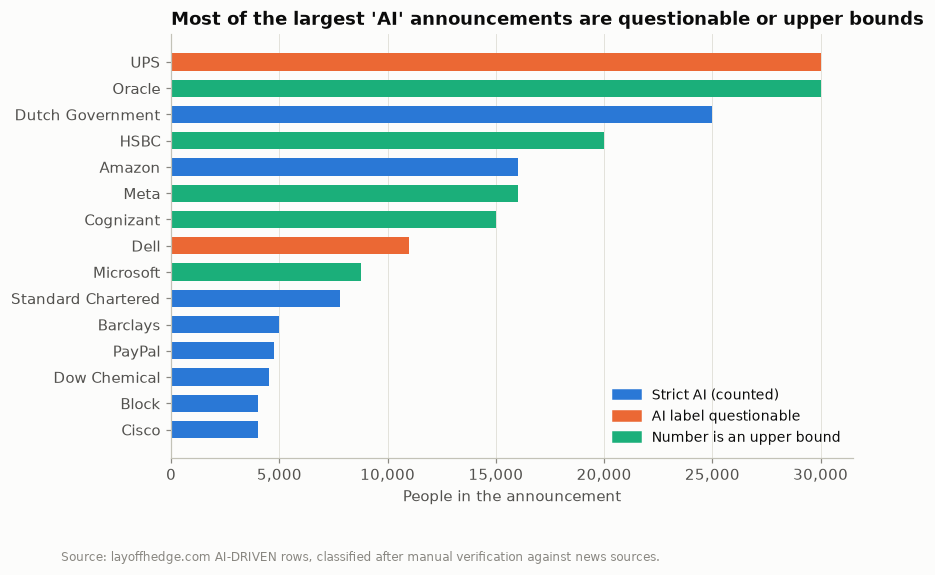

AI share of people — strict: 16.9% | broad (upper bound): 38.4%
'Broad only' rows: 18, median 1,750 people


,people_cut,month,class
company,,,
Oracle,30000,2026-03,Number is an upper bound
UPS,30000,2026-01,AI label questionable
Dutch Government,25000,2026-10,Strict AI (counted)
HSBC,20000,2026-03,Number is an upper bound
Meta,16000,2026-03,Number is an upper bound
Amazon,16000,2026-01,Strict AI (counted)
Cognizant,15000,2026-04,Number is an upper bound
Dell,11000,2026-03,AI label questionable
Microsoft,8750,2026-04,Number is an upper bound


In [4]:
ai_rows = main[main["is_ai_driven"]].copy()
ai_rows["class"] = np.select(
    [ai_rows["is_ai_strict"], ai_rows["ai_label_questionable"]],
    ["Strict AI (counted)", "AI label questionable"], default="Number is an upper bound")
top = ai_rows.nlargest(15, "people_cut").sort_values("people_cut")
palette = {"Strict AI (counted)": BLUE, "AI label questionable": ORANGE, "Number is an upper bound": AQUA}

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top["company"], top["people_cut"], color=top["class"].map(palette), height=0.66)
ax.xaxis.set_major_formatter(thousands)
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=col, label=name) for name, col in palette.items()],
          loc="lower right", fontsize=9)
ax.set_xlabel("People in the announcement")
ax.set_title("Most of the largest 'AI' announcements are questionable or upper bounds")
source_note(fig, "Source: layoffhedge.com AI-DRIVEN rows, classified after manual verification against news sources.")
save(fig, "03_strict_vs_broad")
plt.show()

strict_share = main.loc[main["is_ai_strict"], "people_cut"].sum() / main["people_cut"].sum() * 100
broad_share = main.loc[main["is_ai_driven"], "people_cut"].sum() / main["people_cut"].sum() * 100
broad_only = ai_rows[~ai_rows["is_ai_strict"]]
print(f"AI share of people — strict: {strict_share:.1f}% | broad (upper bound): {broad_share:.1f}%")
print(f"'Broad only' rows: {len(broad_only)}, median {broad_only['people_cut'].median():,.0f} people")
display(top[["company", "people_cut", "month", "class"]].sort_values("people_cut", ascending=False).set_index("company"))

**Reading it:** of the seven largest AI-labelled rows, only Amazon and the Dutch Government survive the strict definition. The 18 "broad only" rows have a median of **1,750 people** — they are what inflates the broad share. The headline therefore uses the strict definition: **about one in six people (16.9%)** in announced job cuts is attributed to AI; 38.4% is only an upper bound.

## 4. Q2 — In which industries was AI cited more often?

Each industry shows the **strict** share (filled dot) and the **broad** upper bound (hollow dot). Industries with fewer than 10 announcements are marked: one announcement decides their share.

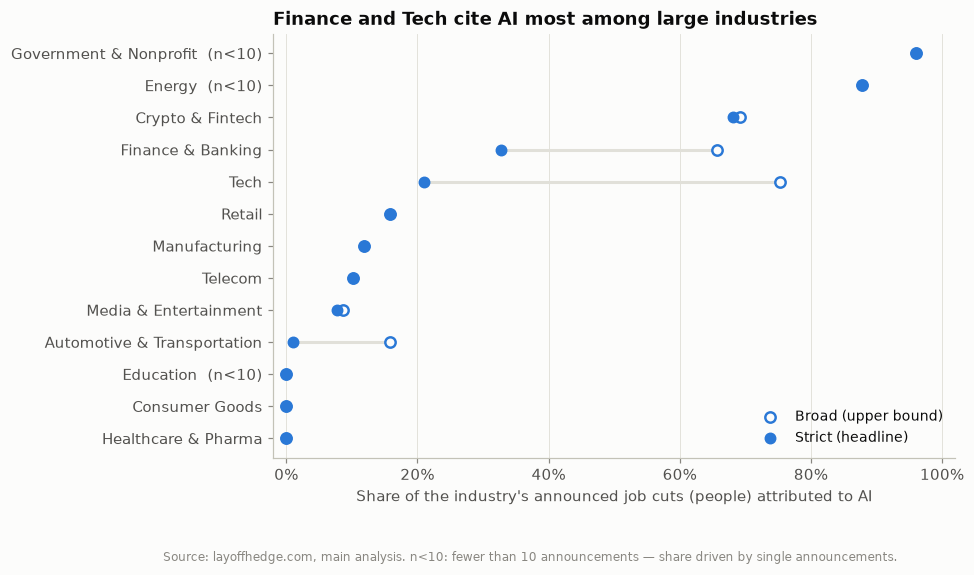

,announcements,ai_strict_announcements,ai_strict_share_pct,ai_share_pct_upper
industry,,,,
Government & Nonprofit,7,1,96.1,96.1
Energy,2,1,87.8,87.8
Crypto & Fintech,22,9,68.1,69.2
Finance & Banking,59,9,32.7,65.7
Tech,139,42,21.0,75.3
Retail,46,3,15.8,15.8
Manufacturing,86,1,11.9,11.9
Telecom,12,1,10.2,10.2
Media & Entertainment,62,6,7.7,8.6


In [5]:
q2 = industries.sort_values("ai_strict_share_pct").copy()
q2["label"] = np.where(q2["announcements"] < 10, q2["industry"] + f"  (n<10)", q2["industry"])
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(q2))
ax.hlines(y, q2["ai_strict_share_pct"], q2["ai_share_pct_upper"], color=GRID, linewidth=2)
ax.scatter(q2["ai_share_pct_upper"], y, s=46, facecolor=SURFACE, edgecolor=BLUE, linewidth=1.6,
           label="Broad (upper bound)", zorder=3)
ax.scatter(q2["ai_strict_share_pct"], y, s=46, color=BLUE, label="Strict (headline)", zorder=4)
ax.set_yticks(y, q2["label"])
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_xlim(-2, 102)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", fontsize=9)
ax.set_xlabel("Share of the industry's announced job cuts (people) attributed to AI")
ax.set_title("Finance and Tech cite AI most among large industries")
source_note(fig, "Source: layoffhedge.com, main analysis. n<10: fewer than 10 announcements — share driven by single announcements.")
save(fig, "04_q2_ai_by_industry")
plt.show()

display(industries.set_index("industry")[["announcements", "ai_strict_announcements",
                                          "ai_strict_share_pct", "ai_share_pct_upper"]]
        .sort_values("ai_strict_share_pct", ascending=False))

**Answer:** among industries with a meaningful number of announcements, **Crypto & Fintech (68%)**, **Finance & Banking (33%)** and **Tech (21%)** attribute the largest share of their cuts to AI. Health care, consumer goods and education cite AI **never**; automotive almost never (1% — the large UPS row is questionable). Government (96%) and Energy (88%) rest on 7 and 2 announcements and are not interpreted. The gap between dots shows how much the broad label overstates Tech (75% → 21%).

## 5. Q3 — How did the AI share change month by month?

Two ways to measure it:
- **Announcement-count share:** the share of announcements that cite AI. Not affected by the size of single announcements.
- **People share:** the share of people in AI-attributed cuts. One giant announcement can decide a month.

Both are compared with **Challenger, Gray & Christmas**, an independent monthly report on US job cuts. Both panels use the same y-axis.

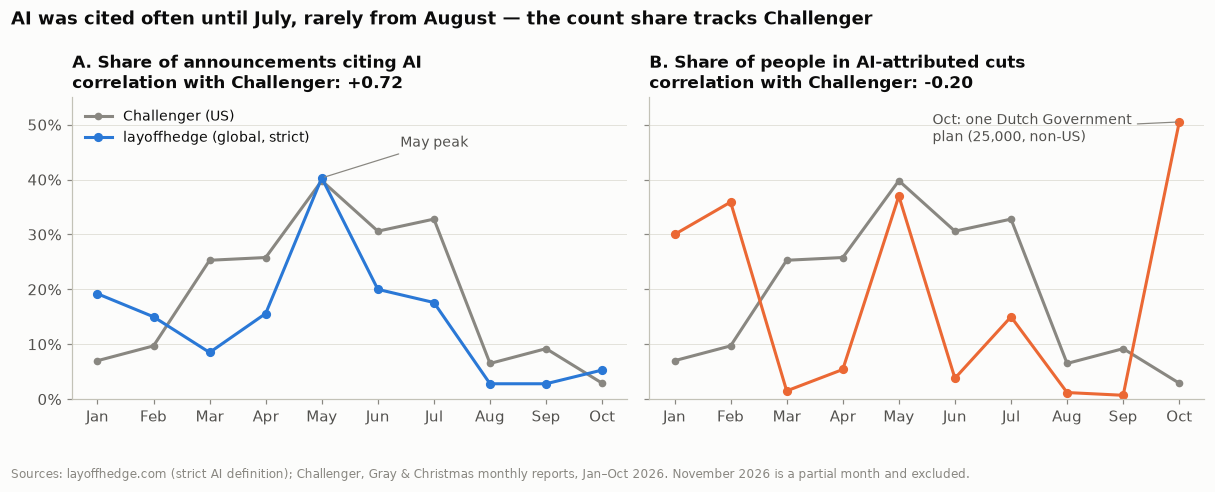

,announcements,ai_strict_count_share_pct,ai_strict_share_pct,challenger
month,,,,
2026-01,26,19.2,30.0,7.0
2026-02,20,15.0,35.9,9.7
2026-03,47,8.5,1.5,25.3
2026-04,32,15.6,5.4,25.8
2026-05,62,40.3,37.0,39.8
2026-06,40,20.0,3.8,30.6
2026-07,51,17.6,15.0,32.8
2026-08,72,2.8,1.2,6.5
2026-09,106,2.8,0.7,9.2


In [6]:
m = monthly[monthly["month"] <= "2026-10"].merge(
    challenger[["month", "ai_share_pct"]].rename(columns={"ai_share_pct": "challenger"}), on="month")
m["label"] = pd.to_datetime(m["month"]).dt.strftime("%b")
x = np.arange(len(m))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
panels = [("ai_strict_count_share_pct", "A. Share of announcements citing AI", BLUE),
          ("ai_strict_share_pct", "B. Share of people in AI-attributed cuts", ORANGE)]
for ax, (col, title, color) in zip(axes, panels):
    ax.plot(x, m["challenger"], color=MUTED, marker="o", markersize=4, label="Challenger (US)")
    ax.plot(x, m[col], color=color, marker="o", markersize=5, label="layoffhedge (global, strict)")
    ax.set_xticks(x, m["label"])
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    r = m["challenger"].corr(m[col])
    ax.set_title(f"{title}\ncorrelation with Challenger: {r:+.2f}", fontsize=11)
    ax.grid(axis="x", visible=False)
axes[0].annotate("May peak", (4, m.loc[4, "ai_strict_count_share_pct"]), xytext=(5.4, 46),
                 fontsize=9, color=INK_2, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
axes[1].annotate("Oct: one Dutch Government\nplan (25,000, non-US)", (9, m.loc[9, "ai_strict_share_pct"]),
                 xytext=(4.6, 47), fontsize=9, color=INK_2, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
axes[0].legend(loc="upper left", fontsize=9)
axes[0].set_ylim(0, 55)
fig.suptitle("AI was cited often until July, rarely from August — the count share tracks Challenger",
             x=0.0, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
source_note(fig, "Sources: layoffhedge.com (strict AI definition); Challenger, Gray & Christmas monthly reports, Jan–Oct 2026. "
                 "November 2026 is a partial month and excluded.")
save(fig, "05_q3_monthly_ai_share")
plt.show()

display(m.set_index("month")[["announcements", "ai_strict_count_share_pct", "ai_strict_share_pct", "challenger"]])

**Answer:** AI was a common stated reason in the first seven months (8–20% of announcements, **peak in May at 40%**) and became rare from August (**3–6%**). Challenger's independent US data shows the same pattern (peak May 39.8%, low October 2.9%; correlation **+0.72**).

**Why two measures matter:** the people share (panel B) does *not* track Challenger (correlation −0.20), because single giant announcements decide a month — October jumps to 50% only because of the Dutch Government's 25,000-person plan spread until 2035. The count share is the right measure for the trend.

*Caveat:* 10 months is a short series; the correlation confirms **direction**, it is not proof. Challenger covers the US only; layoffhedge is global.

## 6. Q4 — Do AI-attributed announcements cover more people?

Announcement sizes are very skewed (from 19 to 50,000 people), so the chart uses a **log scale** and compares **medians**, not means.

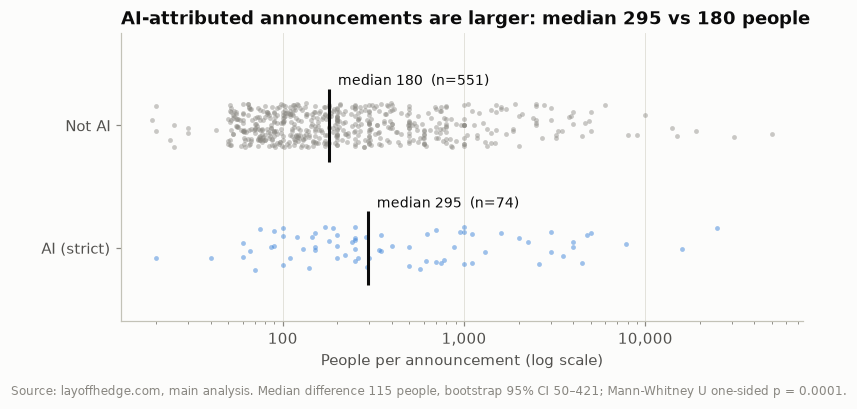

,announcements,median_people,mean_people,median_company_size
AI (strict),74.0,295.0,1494.0,4437.5
Not AI,551.0,180.0,731.0,10000.0


In [7]:
groups = [("AI (strict)", main.loc[main["is_ai_strict"], "people_cut"], BLUE),
          ("Not AI", main.loc[~main["is_ai_driven"], "people_cut"], MUTED)]
rng = np.random.default_rng(1)
fig, ax = plt.subplots(figsize=(8, 3.4))
for i, (name, values, color) in enumerate(groups):
    jitter = rng.uniform(-0.18, 0.18, len(values))
    ax.scatter(values, i + jitter, s=10, color=color, alpha=0.45, linewidths=0)
    med = values.median()
    ax.vlines(med, i - 0.3, i + 0.3, color=INK, linewidth=2)
    ax.text(med * 1.12, i + 0.33, f"median {med:,.0f}  (n={len(values)})", fontsize=9, color=INK)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(thousands)
ax.set_yticks([0, 1], [g[0] for g in groups])
ax.set_ylim(-0.6, 1.75)
ax.grid(axis="y", visible=False)
ax.set_xlabel("People per announcement (log scale)")
ax.set_title("AI-attributed announcements are larger: median 295 vs 180 people")
t = tests.loc["1a_median_diff_ai_strict_minus_non_ai"]
p = tests.loc["1b_mann_whitney_ai_greater", "p_value"]
source_note(fig, f"Source: layoffhedge.com, main analysis. Median difference {t['value']:.0f} people, bootstrap 95% CI "
                 f"{t['ci95_low']:.0f}–{t['ci95_high']:.0f}; Mann-Whitney U one-sided p = {p:.4f}.")
save(fig, "06_q4_announcement_size")
plt.show()

size = pd.DataFrame({name: {"announcements": len(v), "median_people": v.median(), "mean_people": round(v.mean())}
                     for name, v, _ in groups}).T
size.loc["AI (strict)", "median_company_size"] = main.loc[main["is_ai_strict"], "total_workforce"].median()
size.loc["Not AI", "median_company_size"] = main.loc[~main["is_ai_driven"], "total_workforce"].median()
display(size)

**Answer:** yes. The median AI-attributed announcement covers **295 people**, versus **180** for other announcements. The difference (115 people) has a bootstrap 95% confidence interval of 50–421 people — it does not include zero — and the Mann-Whitney test gives p < 0.001.

**What it does *not* mean:** AI is not cited mainly by large companies. Companies citing AI are actually *smaller* (median 4,438 employees vs 10,000). An earlier version of this project claimed the opposite; the robustness check showed it does not hold, so the claim was dropped.

## 7. Q5 — How did the share of job postings mentioning AI change?

Indeed Hiring Lab measures the share of job postings that **mention AI**. This is not the same as demand for AI skills: postings of companies selling AI products, and "we use AI in hiring" disclosures, count too. Canada is left out: an Ontario law made such disclosures mandatory in 2026, which inflates the Canadian series.

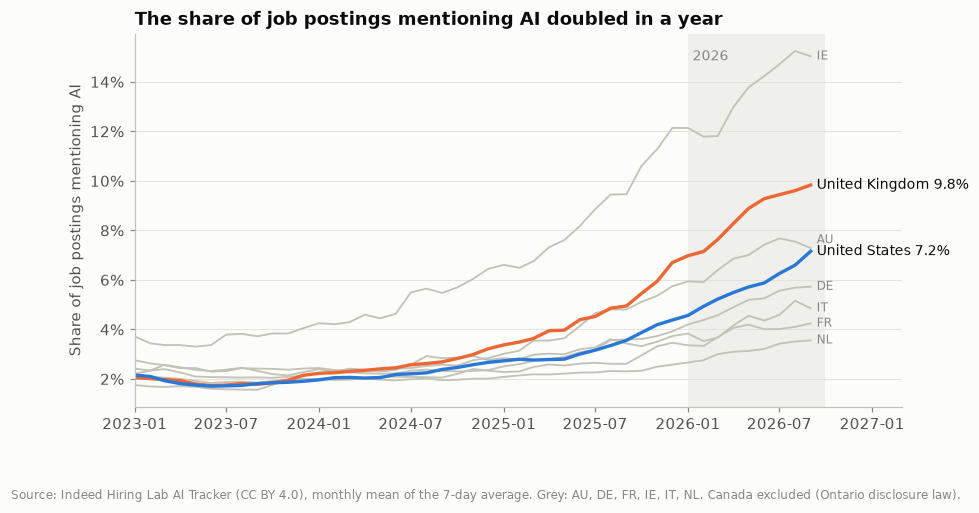

month,2025-09,2026-09,change_pt,comparable
country_name,,,,
Canada,5.61,18.39,12.78,False
Ireland,9.46,15.03,5.57,True
United Kingdom,4.94,9.83,4.89,True
Australia,4.80,7.29,2.49,True
United States,3.56,7.16,3.60,True
Germany,3.59,5.73,2.14,True
Italy,3.43,4.86,1.43,True
France,2.61,4.24,1.63,True
Netherlands,2.31,3.56,1.25,True


In [8]:
ind_m = indeed[(indeed["country_code"] != "CA") & (indeed["month"] >= "2023-01")].copy()
ind_m["date"] = pd.to_datetime(ind_m["month"])
fig, ax = plt.subplots(figsize=(9, 4.4))
highlight = {"GB": (ORANGE, "United Kingdom"), "US": (BLUE, "United States")}
end_labels = []
for code_, g in ind_m.groupby("country_code"):
    if code_ in highlight:
        continue
    ax.plot(g["date"], g["ai_share_pct"], color=GREY_SERIES, linewidth=1.2)
    end_labels.append([g["ai_share_pct"].iloc[-1], code_, MUTED, 8])
for code_, (color, name) in highlight.items():
    g = ind_m[ind_m["country_code"] == code_]
    ax.plot(g["date"], g["ai_share_pct"], color=color, linewidth=2.2)
    end_labels.append([g["ai_share_pct"].iloc[-1], f"{name} {g['ai_share_pct'].iloc[-1]:.1f}%", INK, 9])
# spread the end labels so they never overlap (minimum vertical gap)
end_labels.sort(key=lambda e: e[0])
for i in range(1, len(end_labels)):
    end_labels[i][0] = max(end_labels[i][0], end_labels[i - 1][0] + 0.45)
x_end = ind_m["date"].max() + pd.Timedelta(days=12)
for y_pos, text, color, size in end_labels:
    ax.text(x_end, y_pos, text, fontsize=size, color=color, va="center")
ax.axvspan(pd.Timestamp("2026-01-01"), pd.Timestamp("2026-09-30"), color=GRID, alpha=0.45, linewidth=0)
ax.text(pd.Timestamp("2026-01-10"), ax.get_ylim()[1] * 0.96, "2026", fontsize=9, color=MUTED, va="top")
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.grid(axis="x", visible=False)
ax.set_xlim(pd.Timestamp("2023-01-01"), pd.Timestamp("2027-03-01"))
ax.set_ylabel("Share of job postings mentioning AI")
ax.set_title("The share of job postings mentioning AI doubled in a year")
source_note(fig, "Source: Indeed Hiring Lab AI Tracker (CC BY 4.0), monthly mean of the 7-day average. "
                 "Grey: AU, DE, FR, IE, IT, NL. Canada excluded (Ontario disclosure law).")
save(fig, "07_q5_indeed")
plt.show()

yoy = (indeed[indeed["month"].isin(["2025-09", "2026-09"])]
       .pivot(index="country_name", columns="month", values="ai_share_pct"))
yoy["change_pt"] = yoy["2026-09"] - yoy["2025-09"]
yoy["comparable"] = indeed[indeed["month"] == "2026-09"].set_index("country_name")["comparable"]
display(yoy.sort_values("2026-09", ascending=False).round(2))

**Answer:** between September 2025 and September 2026 the share of postings mentioning AI went from **3.6% to 7.2% in the US** and from **4.9% to 9.8% in the UK** — roughly a doubling. It rose in all eight comparable countries; Ireland has the highest level (15.0%).

## 8. Both sides together

The two series measure different things on different scales, so they are shown as two panels on a shared time axis rather than on one chart with two y-axes. The window is January–September 2026, where all sources overlap.

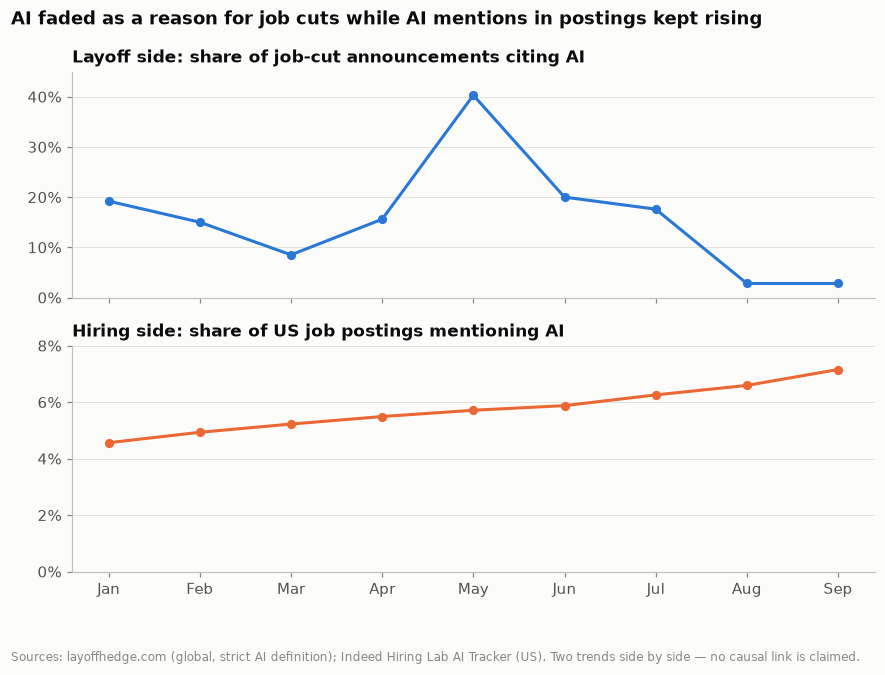

Correlation Jan–Sep 2026: -0.38 (n = 9 months)


In [9]:
both = m[m["month"] <= "2026-09"].merge(
    indeed[indeed["country_code"] == "US"][["month", "ai_share_pct"]].rename(columns={"ai_share_pct": "indeed_us"}),
    on="month")
xb = np.arange(len(both))
fig, (top_ax, bottom_ax) = plt.subplots(2, 1, figsize=(8, 5.6), sharex=True)
top_ax.plot(xb, both["ai_strict_count_share_pct"], color=BLUE, marker="o", markersize=5)
top_ax.set_ylim(0, 45)
top_ax.set_title("Layoff side: share of job-cut announcements citing AI", fontsize=11)
bottom_ax.plot(xb, both["indeed_us"], color=ORANGE, marker="o", markersize=5)
bottom_ax.set_ylim(0, 8)
bottom_ax.set_title("Hiring side: share of US job postings mentioning AI", fontsize=11)
for ax in (top_ax, bottom_ax):
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(axis="x", visible=False)
bottom_ax.set_xticks(xb, both["label"])
fig.suptitle("AI faded as a reason for job cuts while AI mentions in postings kept rising",
             x=0.0, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
source_note(fig, "Sources: layoffhedge.com (global, strict AI definition); Indeed Hiring Lab AI Tracker (US). "
                 "Two trends side by side — no causal link is claimed.")
save(fig, "08_both_sides")
plt.show()
print(f"Correlation Jan–Sep 2026: {both['indeed_us'].corr(both['ai_strict_count_share_pct']):+.2f} (n = {len(both)} months)")

**Reading it:** in 2026 AI became **less** common as a stated reason for job cuts and **more** common in job postings. This is the central picture of the project — shown side by side, **without a causal claim**. The scopes differ (layoffhedge is global, the Indeed series is the US), so the comparison is about direction, not about the same population.

## 9. How robust are the findings?

Three checks from `python/robustness_check.py` and `python/statistical_tests.py`:
1. **Reliability levels:** do the findings hold when only verified rows are used?
2. **Split month:** August was chosen as the break point after looking at the data. Does the decline depend on that choice?
3. **Uncertainty of the headline:** how precise is 16.9%?

,1_all_rows,2_core_T1_T3,3_manual_only_T1_T2
rows,643,313,133
people_share_of_all_%,100.0,81.6,72.3
industry_1,Automotive & Transportation,Automotive & Transportation,Automotive & Transportation
industry_2,Tech,Tech,Tech
industry_3,Finance & Banking,Finance & Banking,Finance & Banking
people_share_strict_jan_apr_mean_%,18.2,22.3,23.4
people_share_strict_jun_sep_mean_%,5.2,6.6,13.0
ai_strict_median_people,295.0,320.0,320.0
non_ai_median_people,180.0,200.0,3000.0


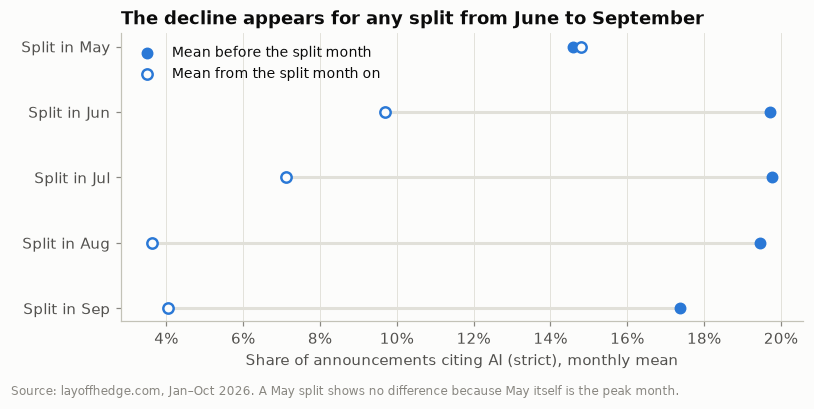

,value,ci95_low,ci95_high,p_value
test,,,,
2a_ai_people_share_strict_%,16.92,8.82,27.45,NaN
2b_ai_people_share_broad_%,38.36,23.98,52.00,NaN
2c_ai_count_share_strict_%,11.51,9.02,14.00,NaN
4a_corr_challenger_vs_count_share,0.72,NaN,NaN,0.0056
5d_ai_share_strict_scenario_C_rate_x_mean_%,18.12,NaN,NaN,NaN


In [10]:
rob = pd.read_csv(DATA / "robustness_check.csv", index_col=0)
rob_view = rob.loc[["rows", "people_share_of_all_%", "industry_1", "industry_2", "industry_3",
                    "people_share_strict_jan_apr_mean_%", "people_share_strict_jun_sep_mean_%",
                    "ai_strict_median_people", "non_ai_median_people"]]
display(rob_view)

splits = tests[tests.index.str.startswith("3_split")].copy()
splits["split"] = pd.to_datetime(splits.index.str.extract(r"(\d{4}-\d{2})")[0].to_numpy()).strftime("%b")
fig, ax = plt.subplots(figsize=(8, 3.4))
ys = np.arange(len(splits))[::-1]
ax.hlines(ys, splits["ci95_high"], splits["ci95_low"], color=GRID, linewidth=2)
ax.scatter(splits["ci95_low"], ys, s=46, color=BLUE, zorder=3, label="Mean before the split month")
ax.scatter(splits["ci95_high"], ys, s=46, facecolor=SURFACE, edgecolor=BLUE, linewidth=1.6, zorder=3,
           label="Mean from the split month on")
ax.set_yticks(ys, [f"Split in {s}" for s in splits["split"]])
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
ax.legend(loc="upper left", fontsize=9)
ax.set_xlabel("Share of announcements citing AI (strict), monthly mean")
ax.set_title("The decline appears for any split from June to September")
source_note(fig, "Source: layoffhedge.com, Jan–Oct 2026. A May split shows no difference because May itself is the peak month.")
save(fig, "09_split_sensitivity")
plt.show()

ci = tests.loc[["2a_ai_people_share_strict_%", "2b_ai_people_share_broad_%", "2c_ai_count_share_strict_%",
                "4a_corr_challenger_vs_count_share", "5d_ai_share_strict_scenario_C_rate_x_mean_%"],
               ["value", "ci95_low", "ci95_high", "p_value"]]
display(ci)

**Reading it:**
- The top three industries and the direction of the AI trend are the **same at every reliability level**.
- The decline does **not** depend on choosing August: any split from June to September shows it, in both sources.
- The headline 16.9% is **imprecise** (bootstrap 95% CI 8.8–27.5%) because a few giant rows carry it — hence "about one in six". The announcement-count share is much more stable (11.5%, CI 9.0–14.0%).
- Even if AI labels were missed among the less-checked non-AI rows at the observed rate, the strict share would rise to at most ~18%.

## 10. Summary

| Question | Answer |
|---|---|
| Q1 — Industries | Automotive & Transportation (31%), Tech (24%), Finance & Banking (11%) of people in announced cuts |
| Q2 — Where AI is cited | Crypto & Fintech 68%, Finance 33%, Tech 21% (strict); never in health care, consumer goods, education |
| Q3 — Over time | AI in 8–20% of announcements Jan–Jul (peak May 40%), 3–6% from August; confirmed by Challenger (r = 0.72) |
| Q4 — Size | AI announcements are larger: median 295 vs 180 people (CI of the difference 50–421) — but not from larger companies |
| Q5 — Job postings | Share of postings mentioning AI doubled in a year: US 3.6% → 7.2%, UK 4.9% → 9.8% |

**What the data suggests for junior candidates (interpretation, not a finding):** during 2026, AI showed up less and less as a stated reason for job cuts and more and more in job postings. For job seekers, AI looks less like a layoff threat and more like a requirement in postings. The data contains **no seniority information**, so this is not tested for junior roles specifically.

**Limitations:** only announced, reported cuts; no country column in the layoff data; different scopes (layoffhedge global, Indeed 9 countries without Turkey, Challenger US); "posting mentions AI" is not the same as AI-skill demand; 10-month series; November 2026 is partial. Full list: `docs/DATA_QUALITY.md`.